# 14 Freitexte der Begehungen: Fehlerrangliste und bessere Labels

Teil 4: Stationsbilder und Befunde

**Worum es geht**
- Bisher wurde gegen die Alt-Neu-Spalten der Begehungstabelle geprüft (Heizzeiten, Rücklaufsollwerte, Warmwasserzeiten).
- Dort liegt der Kennlinienmonitor aus Notebook 13 nur rund 30 % über Zufall.
- 57 der 66 Begehungen haben zusätzlich eine Freitextnotiz. Sie war bisher ungenutzt.
- Verdacht: mechanische Arbeiten stehen nur im Freitext. Dann ist der bisherige Maßstab unvollständig.

**Daten**
- liest: Begehungstabelle, Stundenreihen in `data/processed/real_meters`
- schreibt: nichts
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/befundcodes.py` (Kodierung) und `src/kennlinien_monitor.py` (Gegenprobe), Tests in `tests/test_befundcodes.py` und `tests/test_kennlinien_monitor.py`

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import befundcodes as bc
from src import kennlinien_monitor as km
from src import load_begehungen as lb
from src import ternaer as tn

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

METER_DIR = ROOT / "data" / "processed" / "real_meters"

kodiert = bc.kodiere_begehungen()
print(f"{len(kodiert)} Begehungen")
print(f"{int(kodiert['text_vorhanden'].sum())} mit Freitext")
print(f"{int(kodiert['datum'].notna().sum())} mit Datum")
print(f"{int(kodiert['meter'].notna().sum())} mit Zaehlernummer")

66 Begehungen
57 mit Freitext
58 mit Datum
66 mit Zaehlernummer


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


## 1 Warum die strukturierten Spalten nicht reichen

- Beispiel Zähler 68956351: derselbe Termin einmal in den Alt-Neu-Spalten, einmal im Freitext.

In [2]:
fall = kodiert[kodiert["meter"] == 68956351]
alt_neu = [sp for paar in bc._ALT_NEU for sp in paar if sp in fall.columns]
print("Termin:", fall["datum"].iloc[0].date())
print("\nStrukturierte Spalten:")
print(fall[alt_neu].T.to_string())
print("\nFreitext:")
print(fall["sonstiges"].iloc[0])

Termin: 2024-09-09

Strukturierte Spalten:
                         19
heizzeit_alt_von   06:00:00
heizzeit_neu_von   06:00:00
heizzeit_alt_bis   22:00:00
heizzeit_neu_bis   22:00:00
tww_alt_von        00:00:00
tww_neu_von        06:00:00
tww_alt_bis        23:59:59
tww_neu_bis        22:00:00
rw_soll_tag_alt          20
rw_soll_tag_neu          18
rw_soll_nacht_alt        15
rw_soll_nacht_neu        15
tww_soll_alt             52
tww_soll_neu             52

Freitext:
Sind Stellventile Programmierbar Schmutzfänger stark voll Baujahr 11 Station von 2014 WP für teilweise TWW Beratung Stellmotor getauscht AMV 130 gegen AMV 150 Fußbodenheizung Holzständer


- Spalten: Rücklaufsollwert am Tag von 20 auf 18 °C, Warmwasserzeit von durchgehend auf 06:00 bis 22:00 Uhr.
- Freitext: „Stellmotor getauscht AMV 130 gegen AMV 150“ und ein stark gefüllter Schmutzfänger.
- Laut Spalten also nur eine Reglereinstellung, tatsächlich ein Tausch des Stellmotors. Drei Tage später zeigt der Monitor hier seinen größten Ausschlag.
- Kein Flüchtigkeitsfehler: für mechanische Arbeiten gibt es in den Spalten kein Feld.

## 2 Wie die Freitexte kodiert werden

- Die Notizen sind im Telegrammstil geschrieben, ohne Satzzeichen und mit Tippfehlern („Stellantireb gewechselt“).
- Feste Regeln statt Sprachmodell: bei 57 Notizen ist jede Regel von Hand prüfbar und wiederholbar. Je Kategorie gibt es Treffermuster, eine Notiz kann mehrere Kategorien haben.
- Verneinungen fängt ein Veto ab, nur kurz hinter dem Treffer („Schmutzfänger fast leer“ ist kein Befund).
- Ein Veto nach links würde fremde Befunde löschen: „rw Pumpoe läuft nicht über Regler“ und „at Fühler passt“ stehen nur 26 Zeichen auseinander.

In [3]:
regeln = pd.DataFrame([
    {"kategorie": name,
     "treffer": ", ".join(r["treffer"][:4]),
     "veto_danach": ", ".join(r["veto_danach"]) or "-",
     "veto_davor": ", ".join(r["veto_davor"]) or "-"}
    for name, r in bc.BEFUNDE.items()])
print(regeln.to_string(index=False))

             kategorie                                                                              treffer                                     veto_danach                    veto_davor
        schmutzfaenger                                            schmutzfaenger, schmutzfilter, \bfilter\b ^ (fast )?leer, ^ sauber, ^ passt, ^ in ordnung                             -
   ventil_stellantrieb                                   regelventil, stellventil, stellmot\w*, stellant\w*                           ^ passt, ^ in ordnung                             -
      regler_parameter             anlagenkennziffer, anlagenschema, anlagenkonfiguration, regler verstellt                           ^ passt, ^ in ordnung                             -
           zirkulation                            zirk\w* pumpe, zirkulationspumpe, \bzirk\b, \bzirkulation                           ^ passt, ^ in ordnung schwerkraft\s*$, natur\w*\s*$
                 pumpe                          heizkreispumpe, rw pum

In [4]:
#die vier Fälle, an denen sich das Veto entscheidet
proben = ["Schmutzfänger stark voll",
          "Schmutzfänger fast leer",
          "Zirk abgeklemmt",
          "Schwerkraft Zirkulation Gleiderheizkörper",
          "rw Pumpoe läuft nicht über Regler at Fühler passt"]
for text in proben:
    treffer = [n for n in bc.BEFUNDE if bc.kodiere_text(text)[n]]
    print(f"{text:50s} -> {treffer}")

Schmutzfänger stark voll                           -> ['schmutzfaenger']
Schmutzfänger fast leer                            -> []
Zirk abgeklemmt                                    -> ['zirkulation']
Schwerkraft Zirkulation Gleiderheizkörper          -> []
rw Pumpoe läuft nicht über Regler at Fühler passt  -> ['pumpe']


- Zusätzlich gibt es Kontextlabels: Fußbodenheizung, Heizkörper, Holzfeuerung, Naturumlauf, Baujahr.
- Das sind keine Fehler, sie helfen aber beim Lesen der Zeitreihen.
- „Naturzirkulation“ zählt deshalb als Bauart, nicht als Zirkulationsfehler.

## 3 Die Fehlerrangliste

- Wie oft nennen die Notizen welchen Befund?
- Nenner sind die 57 Begehungen mit Freitext.

In [5]:
rang = bc.rangliste(kodiert)
print(rang.to_string(index=False))

verteilung = (kodiert[kodiert["text_vorhanden"]]["n_befunde"]
              .value_counts().sort_index())
print("\nBefunde je Notiz:")
print(verteilung.to_string())

                befund  n  nenner   anteil
   ventil_stellantrieb  9      57 0.157895
      regler_parameter  9      57 0.157895
        schmutzfaenger  6      57 0.105263
hydraulik_volumenstrom  5      57 0.087719
           zirkulation  4      57 0.070175
                 pumpe  4      57 0.070175
              daemmung  4      57 0.070175
           messtechnik  3      57 0.052632
            anlage_aus  3      57 0.052632

Befunde je Notiz:
n_befunde
0    25
1    21
2     8
3     2
4     1


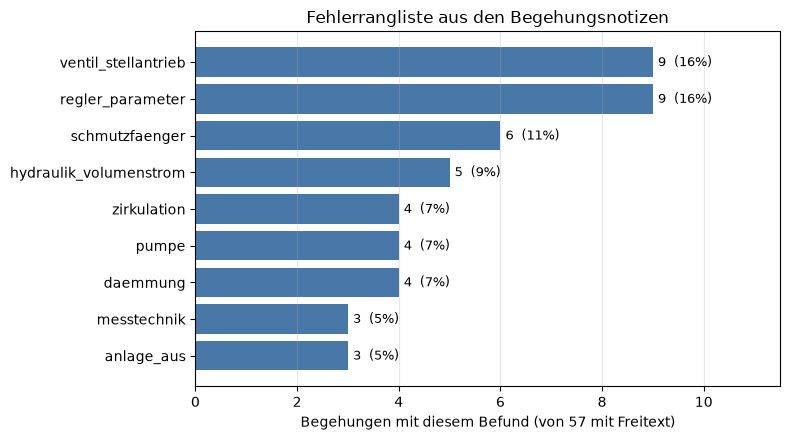

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(rang["befund"][::-1], rang["n"][::-1], color="#4878a8")
ax.set_xlabel("Begehungen mit diesem Befund (von 57 mit Freitext)")
ax.set_title("Fehlerrangliste aus den Begehungsnotizen")
for y, (n, anteil) in enumerate(zip(rang["n"][::-1], rang["anteil"][::-1])):
    ax.text(n + 0.1, y, f"{n}  ({anteil:.0%})", va="center", fontsize=9)
ax.set_xlim(0, rang["n"].max() + 2.5)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

- Vorn liegen Stellantrieb/Regelventil und Reglerparameter mit je 9 von 57. Es folgen Schmutzfänger (6), Hydraulik (5) sowie Zirkulation, Pumpe und Dämmung (je 4).
- Das ist die Häufigkeit in den Notizen, nicht im Netz. Die Begehungen sind nicht zufällig ausgewählt, und was nicht notiert ist, fehlt.
- 25 Notizen enthalten keinen Fehlerbefund (Abschnitt 5).

## 4 Was die Alt-Neu-Spalten übersehen

- Je Begehung zwei Fragen: Nennt der Freitext einen Befund? Hat sich ein Alt-Neu-Wert geändert?

In [7]:
tafel = bc.diskrepanzen(kodiert)
breit = tafel.pivot(index="befund_im_text", columns="sollwert_geaendert",
                    values="n").fillna(0).astype(int)
breit.index = ["kein Befund im Text", "Befund im Text"]
breit.columns = ["Sollwert unverändert", "Sollwert geändert"]
print(breit.to_string())
print(f"\nSumme: {int(breit.values.sum())} Begehungen")

                     Sollwert unverändert  Sollwert geändert
kein Befund im Text                    16                 18
Befund im Text                          6                 26

Summe: 66 Begehungen


- 6 von 66 Begehungen nennen einen Fehler ohne Sollwertänderung. Sie galten bisher als Begehung ohne Eingriff.
- 18 Begehungen haben geänderte Sollwerte ohne Befund im Text, 16 haben keins von beidem.
- Keine der beiden Quellen ist vollständig. Die Einteilung nach Eingriff in Notebook 13 stützte sich auf die falsche Spalte.

## 5 Die Notizen ohne Fehlerbefund

- Die 25 Notizen ohne Fehlerlabel wurden von Hand durchgesehen.
- Frage: reine Gebäudebeschreibung oder übersehener Befund?

In [8]:
offen = bc.unkodiert(kodiert)
print(f"{len(offen)} Notizen ohne Fehlerlabel\n")
for _, zeile in offen.iterrows():
    kontexte = [k for k in bc.KONTEXT if zeile.get(k)]
    print(f"{str(zeile['sonstiges'])[:95]:97s} {kontexte}")

25 Notizen ohne Fehlerlabel

Nippel eingeprüft wurde als Defekt gekennzeichnet nachprüfen                                      []
Fühler 02 Zähler plombiert                                                                        []
Beistellofen                                                                                      ['holzfeuerung']
Beistellofen                                                                                      ['holzfeuerung']
Baujahr 2010/10 Heizkörper Fußbodenheizung auf Heizkörperkreis mit drauf, ohne Mischer            ['fussbodenheizung', 'heizkoerper']
Blitzeinschlag 2021 Baujahr 1968 Fenster 16/17 Heizkörpertausch 16/17                             ['heizkoerper']
Naturzirkulation                                                                                  ['naturumlauf']
Baujahr ca. 1970 Schwerkraft Zirkulation Gleiderheizkörper zwei Holzöfen                          ['heizkoerper', 'holzfeuerung', 'naturumlauf']
Heizungdruck 1,7 bar 1 Heizkörpe

- Fast durchweg Anlagenbeschreibungen („Nur Fußbodenheizung“, „BJ 2007 Radiatoren“). Hier ist kein Fehlerlabel richtig.
- Zwei Notizen ohne ableitbares Label: ein Defekt mit unklarem Ort („Nippel eingeprüft wurde als Defekt gekennzeichnet nachprüfen“) und Messwerte ohne Bewertung („Heizungdruck 1,7 bar“, „ca 430 l/h“). Das sind Fälle für eine Rückfrage, nicht für eine weitere Regel.
- Drei Notizen fallen auf „Anlage aus“ (etwa „Haus steht leer 3 Jahre“). Sie erklären Stillstand, der sonst als Anomalie zählen würde.

## 6 Gegenprobe: trifft der Monitor die mechanischen Eingriffe?

- Der Monitor misst das Verhältnis von Durchfluss zu Leistung. Auf einen getauschten Stellmotor oder einen gereinigten Schmutzfänger sollte er reagieren, auf eine verschobene Heizzeit nicht.
- Zwei Kanäle aus Notebook 13: Parameter (Steigung der Kennlinie) und Residuum (Tagesmedian der Abweichung von der gewohnten Kennlinie).
- Mechanisch heißt: Schmutzfänger, Ventil und Stellantrieb, Pumpe, Zirkulation, Hydraulik. Vergleichsgruppe sind alle übrigen der 58 datierten Termine.
- Zufallsbasis: Trefferquote, die allein aus der Zahl der Alarme je Station zu erwarten wäre.

In [9]:
serien = tn.lade_serien(METER_DIR)
ergebnis = km.monitor_alle(serien)
termine = {int(k): list(v)
           for k, v in lb.begehung_dates_by_meter().items()}

pruefung = km.validiere(ergebnis["alarme"], termine)
basis = km.zufallsbasis(ergebnis["alarme"], ergebnis["abdeckung"], termine)
print(f"{len(ergebnis['alarme'])} Alarme, {len(pruefung)} Pruefzeilen")
print("\nGesamtquote ueber alle Termine:")
print(km.trefferquote(pruefung).to_string(index=False))
print("\nZufallsbasis:")
print(basis.to_string(index=False))

1141 Alarme, 116 Pruefzeilen

Gesamtquote ueber alle Termine:
   quelle        kennzahl  faelle  treffer    quote  median_abstand_tage
parameter        steigung      58       25 0.431034                  8.0
 residuum residuum_median      58       21 0.362069                  9.0

Zufallsbasis:
   quelle        kennzahl  stationen  alarme_je_station  erwartete_quote
parameter        steigung         51           6.823529         0.376779
 residuum residuum_median         51           5.078431         0.296092


/Users/ivelinayaneva/projektseminar/.venv/lib/python3.13/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


In [10]:
MECHANISCH = ["schmutzfaenger", "ventil_stellantrieb", "pumpe",
              "zirkulation", "hydraulik_volumenstrom"]

labels = kodiert[kodiert["datum"].notna() & kodiert["meter"].notna()].copy()
labels["meter"] = labels["meter"].astype(int)
labels["begehung"] = pd.to_datetime(labels["datum"]).dt.normalize()
labels["mechanisch"] = labels[MECHANISCH].any(axis=1)
labels = (labels[["meter", "begehung", "mechanisch", "n_befunde"]]
          .drop_duplicates(subset=["meter", "begehung"]))

gepruft = pruefung.merge(labels, on=["meter", "begehung"], how="left")
erwartet = dict(zip(basis["quelle"], basis["erwartete_quote"]))
print(f"{len(gepruft)} Pruefzeilen, "
      f"{int(gepruft['mechanisch'].sum())} davon mechanisch")

116 Pruefzeilen, 38 davon mechanisch


In [11]:
zeilen = []
for name, maske in [("mechanischer Befund", gepruft["mechanisch"] == True),
                    ("kein mechanischer Befund",
                     gepruft["mechanisch"] == False)]:
    for _, z in km.trefferquote(gepruft[maske]).iterrows():
        erw = erwartet[z["quelle"]]
        test = stats.binomtest(int(z["treffer"]), int(z["faelle"]), erw,
                               alternative="greater")
        zeilen.append({"gruppe": name, "kanal": z["quelle"],
                       "treffer": int(z["treffer"]),
                       "faelle": int(z["faelle"]), "quote": z["quote"],
                       "zufall": erw, "hebel": z["quote"] / erw,
                       "p": test.pvalue})
split = pd.DataFrame(zeilen)
print(split.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

                  gruppe     kanal  treffer  faelle  quote  zufall  hebel     p
     mechanischer Befund parameter        9      19  0.474   0.377  1.257 0.259
     mechanischer Befund  residuum       10      19  0.526   0.296  1.778 0.030
kein mechanischer Befund parameter       16      39  0.410   0.377  1.089 0.390
kein mechanischer Befund  residuum       11      39  0.282   0.296  0.953 0.635


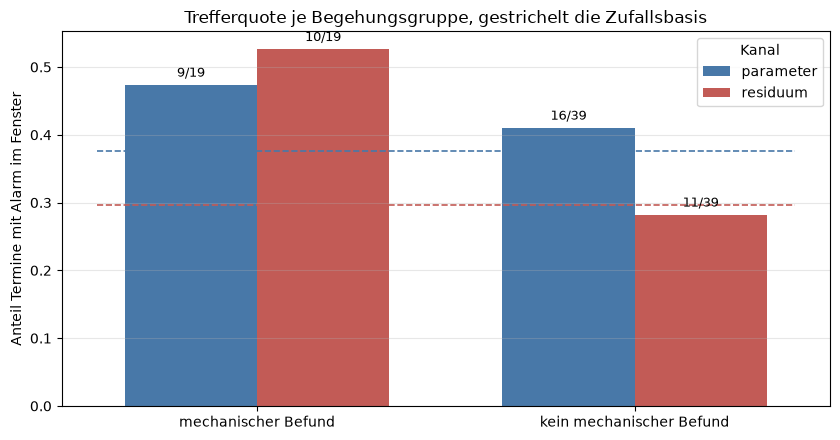

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
gruppen = ["mechanischer Befund", "kein mechanischer Befund"]
kanaele = ["parameter", "residuum"]
breite = 0.35
x = np.arange(len(gruppen))
farben = {"parameter": "#4878a8", "residuum": "#c25b56"}
for i, kanal in enumerate(kanaele):
    teil = split[split["kanal"] == kanal].set_index("gruppe").loc[gruppen]
    ax.bar(x + i * breite, teil["quote"], breite, label=kanal,
           color=farben[kanal])
    for xi, (q, tr, fa) in enumerate(zip(teil["quote"], teil["treffer"],
                                         teil["faelle"])):
        ax.text(xi + i * breite, q + 0.012, f"{tr}/{fa}", ha="center",
                fontsize=9)
    ax.hlines(erwartet[kanal], -0.25, len(gruppen) - 0.4, colors=farben[kanal],
              linestyles="dashed", linewidth=1.2)
ax.set_xticks(x + breite / 2)
ax.set_xticklabels(gruppen)
ax.set_ylabel("Anteil Termine mit Alarm im Fenster")
ax.set_title("Trefferquote je Begehungsgruppe, gestrichelt die Zufallsbasis")
ax.legend(title="Kanal")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

- Der Residuenkanal trifft 10 von 19 Begehungen mit mechanischem Befund (Quote 0,526, Zufallsbasis 0,296). Die übrigen 39 Termine liegen auf Zufallsniveau (0,282).
- Der Parameterkanal zeigt denselben Trend, aber viel schwächer (0,474 gegen 0,410).
- Das passt zur Konstruktion: der Residuenkanal misst Abweichungen vom gewohnten Arbeitspunkt, und der verschiebt sich bei einem Ventiltausch.
- Erste Prüfung im Unsupervised-Strang, die gegen die Ground Truth (Befunde der Begehungen) über den Zufall hinauskommt.

## 7 Hält das einem Test stand?

- Binomialtest: liegt die mechanische Gruppe über der Zufallsbasis?
- Fisher-Test: unterscheiden sich die beiden Gruppen?

In [13]:
res = split[split["kanal"] == "residuum"].set_index("gruppe")
a = int(res.loc["mechanischer Befund", "treffer"])
b = int(res.loc["mechanischer Befund", "faelle"]) - a
c = int(res.loc["kein mechanischer Befund", "treffer"])
d = int(res.loc["kein mechanischer Befund", "faelle"]) - c
odds, p_fisher = stats.fisher_exact([[a, b], [c, d]], alternative="greater")
print(f"Vierfeldertafel Residuum: [[{a}, {b}], [{c}, {d}]]")
print(f"Odds Ratio {odds:.2f}, einseitiger Fisher p = {p_fisher:.4f}")

par = split[split["kanal"] == "parameter"].set_index("gruppe")
a2 = int(par.loc["mechanischer Befund", "treffer"])
b2 = int(par.loc["mechanischer Befund", "faelle"]) - a2
c2 = int(par.loc["kein mechanischer Befund", "treffer"])
d2 = int(par.loc["kein mechanischer Befund", "faelle"]) - c2
odds2, p2 = stats.fisher_exact([[a2, b2], [c2, d2]], alternative="greater")
print(f"Vierfeldertafel Parameter: [[{a2}, {b2}], [{c2}, {d2}]]")
print(f"Odds Ratio {odds2:.2f}, einseitiger Fisher p = {p2:.4f}")

Vierfeldertafel Residuum: [[10, 9], [11, 28]]
Odds Ratio 2.83, einseitiger Fisher p = 0.0644
Vierfeldertafel Parameter: [[9, 10], [16, 23]]
Odds Ratio 1.29, einseitiger Fisher p = 0.4288


- Residuenkanal: gegen Zufall p = 0,030. Im Gruppenvergleich Odds Ratio 2,83 bei p = 0,064. Der Parameterkanal trennt nicht (Odds Ratio 1,29, p = 0,43).
- Kleine Gruppe: ein Fall mehr oder weniger verschiebt die Quote um fünf Prozentpunkte.
- Die Einteilung wurde erst nach dem Nullergebnis in Notebook 13 gewählt. Sauber wäre, sie vorab festzulegen und an neuen Begehungen zu prüfen.
- Tests einseitig, weil die Richtung vorher feststand (zweiseitig p = 0,041 bzw. 0,086). 58 Termine auf 51 Stationen, also nicht völlig unabhängig.

## 8 Gegenprobe: sind die stärksten Alarme nur Zählertausche?

- Einwand: ein neuer Zähler misst anders. Die Kennlinie springt dann, ohne dass sich an der Station etwas ändert.
- Die Zuordnungstabelle zeigt nur, wo die Zählernummer zwischen zwei Jahren wechselt. Ein Tauschdatum fehlt.
- Zwei Zähler an einer Adresse im selben Jahr sind kein Wechsel. Das sind Zuordnungsfehler oder zwei Stationen auf einem Grundstück.

In [14]:
alarme = ergebnis["alarme"].copy()
alarme["betrag"] = alarme["score"].abs()
gewechselt = set(kodiert.loc[kodiert["meter_gewechselt"] == True, "meter"]
                 .dropna().astype(int))
stationen = set(alarme["meter"].astype(int))
top = alarme.sort_values("betrag", ascending=False).head(30)

print(f"Zaehler mit Tausch laut Zuordnung: {len(gewechselt)}")
print(f"davon mit Alarmen: {len(gewechselt & stationen)} "
      f"von {len(stationen)} Alarmstationen")
print(f"Top-30 Alarme auf Tausch-Zaehlern: "
      f"{int(top['meter'].isin(gewechselt).sum())} von 30")
print("\nStaerkste Alarme:")
print(top.head(10)[["meter", "datum", "quelle", "score", "richtung"]]
      .to_string(index=False))

Zaehler mit Tausch laut Zuordnung: 1
davon mit Alarmen: 1 von 92 Alarmstationen
Top-30 Alarme auf Tausch-Zaehlern: 2 von 30

Staerkste Alarme:
   meter               datum    quelle      score richtung
80956410 2024-10-15 00:00:00 parameter -74.169052   runter
68956351 2024-09-12 00:00:00 parameter  73.955304     hoch
68956372 2023-10-19 00:00:00 parameter -56.555137   runter
69513891 2024-07-30 00:00:00 parameter  50.559224     hoch
80912154 2024-11-17 00:00:00 parameter  49.885242     hoch
68956351 2025-06-09 00:00:00 parameter -49.656466   runter
80912190 2024-09-17 00:00:00 parameter  49.422306     hoch
80912190 2024-08-18 00:00:00 parameter  49.330202     hoch
80956410 2025-02-01 00:00:00 parameter  39.531109     hoch
80956410 2024-08-10 00:00:00 parameter -35.458899   runter


- Nur 1 von 92 Alarmstationen hat laut Zuordnung einen Tausch. Ein Tauschartefakt lässt sich so weder zeigen noch ausschließen.
- Die zehn stärksten Alarme verteilen sich auf sechs Stationen und drei Kalenderjahre. Ein Tauschartefakt müsste sich eher zeitlich bündeln. Schwaches Indiz.
- Die Daten zu den Zählerwechseln sind nicht mehr verfügbar. Die Frage bleibt offen.

## 9 Labels je Zähler

- Labels auf Zählerebene, weil Zeitreihen und Features dort hängen.
- Mehrere Begehungen je Zähler werden mit „oder“ verknüpft: ein Befund in einer Begehung reicht.

In [15]:
je_zaehler = bc.labels_je_zaehler(kodiert)
print(f"{len(je_zaehler)} Zaehler mit Labels")
print(f"{int((je_zaehler['n_befunde'] > 0).sum())} davon mit mindestens "
      f"einem Fehlerbefund")
print(f"{int(je_zaehler['baujahr'].notna().sum())} mit Baujahr")
print()
print(je_zaehler.head(10).to_string(index=False))

62 Zaehler mit Labels
32 davon mit mindestens einem Fehlerbefund
20 mit Baujahr

   meter  schmutzfaenger  ventil_stellantrieb  regler_parameter  zirkulation  pumpe  hydraulik_volumenstrom  daemmung  messtechnik  anlage_aus  fussbodenheizung  heizkoerper  holzfeuerung  naturumlauf  n_befunde  baujahr
65273846           False                False             False        False  False                   False     False        False       False             False        False         False        False          0      NaN
68956339           False                False             False         True  False                    True     False        False       False             False         True         False        False          2      NaN
68956340           False                False             False        False  False                   False     False        False       False             False        False         False        False          0      NaN
68956342           False           

- Mehrfachlabel für 62 Zähler statt nur „Maßnahme ja oder nein“. 32 davon haben einen Fehlerbefund, 20 ein Baujahr (Hinweis auf die Heizungsgeneration).
- Für einen Entscheidungsbaum reicht das nicht: die größten Kategorien haben 9 Fälle. Dieselbe Grenze wie beim überwachten Klassifikator (`docs/ml-klassifikator.md`).

## Zusammenfassung & Bewertung

**Ergebnis**
- Die Freitexte enthalten, was in den Alt-Neu-Spalten fehlt: 6 von 66 Begehungen nennen einen Fehler ohne Sollwertänderung, bei 68956351 den Tausch des Stellmotors.
- Mit den neuen Labels trifft der Residuenkanal 10 von 19 mechanischen Begehungen (0,526 gegen Zufallsbasis 0,296, einseitig p = 0,030). Die übrigen Begehungen liegen auf Zufallsniveau.
- Der schwache Befund aus Notebook 13 lag also mindestens teilweise am Maßstab.

**Belastbar**
- Regelbasierte, vollständig nachprüfbare Kodierung. Alle 57 Notizen wurden von Hand geprüft.
- Die 25 Notizen ohne Fehlerlabel sind bis auf drei Fälle reine Anlagenbeschreibungen.

**Schwach**
- Nur 19 Termine, einseitige Tests, Einteilung nach dem Nullergebnis gewählt. Der Gruppenunterschied hat nur p = 0,064.
- Die Rangliste beschreibt die Notizen, nicht das Netz (66 Begehungen bei 93 HAST, nicht zufällig ausgewählt).

**Offen**
- Prüfung an neuen, vorab festgelegten Begehungen.
- Ein Entscheidungsbaum scheitert an der Zahl der Labels.
- Gegenprobe Zählertausch nicht machbar: 1 von 92 Alarmstationen mit Tausch laut Zuordnung, Daten zu den Zählerwechseln nicht mehr verfügbar.
- Zuschnitt der Kategorien (Zirkulation und Pumpe getrennt? Dämmung als Fehler?) und Rückfrage zu den beiden unklaren Notizen.